# Bank Marketing: Decision Tree Classifier
**Maryam Chaudhry | ArithMatrix AVIP 2026 | Data Science Task 4**

This project uses historical bank marketing records to predict whether a customer has signed up for a term deposit. This is a savings product that uses those answers to predict the answers to those questions offered by the bank. The answer is either going to be  **yes** or **no**.

A **decision tree** is a model that works like a flowchart. It learns questions from examples where the answers are already known, then uses those answers to predict the answers to those questions. A **classifier** sorts examples into groups; here, those groups are predicted subscribers and non-subscribers.

The notebook prepares the data, uses one group of records to teach the model, and uses a separate group to check its predictions. It reports the correct predictions, the mistakes and the input information that contributed most to the tree's decisions during training.

The results are saved with charts and a **README**, a written guide explaining the project and how to run it.

**Selected data:** `bank-full.csv` from the UCI Bank Marketing dataset. This is the full, older dataset, not the smaller `bank.csv` sample or the separate `bank-additional-full.csv` version.

**AI assistance:** This notebook was prepared with AI assistance. Model results are calculated from the UCI Bank Marketing dataset.

[Data source: UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)';/nlm



## 1. Install and import the packages

Python packages are collections of ready-made tools. **Installing** makes them available in the notebook's working environment. **Importing** lets the code use the tools it needs.

This project uses `pandas` to organise tables, `numpy` for numerical calculations, `matplotlib` to draw charts, and `scikit-learn` to prepare the data, train the decision tree and measure its results.

Run the code cells in order because later steps use information created by earlier ones.


In [1]:
%pip install -q pandas numpy matplotlib "scikit-learn>=1.3,<2"


In [2]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import URLError
import io
import json
import hashlib
import importlib.metadata
import platform
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix


## 2. Set the project options

These settings control how the model is trained and tested.

**Training and testing:** the model learns from 80% of the prepared records. The other 20% are kept aside to check its predictions on records it did not learn from.

**Repeatable choices:** `RANDOM_STATE = 42` makes the random choices repeatable when the same data, settings and software are used. The number 42 does not make the predictions better.

**Tree depth:** `MAX_DEPTH = 5` allows at most five questions along a route from the top of the tree to a final prediction.

**Minimum group size:** a final group in the tree is called a **leaf**. `MIN_SAMPLES_LEAF = 50` means each leaf must contain at least 50 training records. This stops the tree creating final groups based on only a few examples.

**Class weighting:** there are fewer subscribers than non-subscribers. `CLASS_WEIGHT = "balanced"` gives each subscriber example more influence during training. It does not add records or make the dataset half yes and half no. It may help identify subscribers, but it can also increase incorrect yes predictions.

These settings were chosen before looking at the test scores. They have not been proved to be the best settings.

[Reference: decision-tree settings](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
MAX_DEPTH = 5
MIN_SAMPLES_LEAF = 50
CLASS_WEIGHT = "balanced"

OUTPUT_DIR = Path("task4_output")
REPOSITORY_NAME = "DS_4_DecisionTreeClassifier_BYTE"
NOTEBOOK_NAME = "Bank_Marketing_Decision_Tree_Task_4.ipynb"

# Leave these as None for a fresh UCI download.
# To reuse an exported snapshot, upload both files to Colab and enter their paths.
LOCAL_CSV = None                 # Example: "source_bank_full.csv"
LOCAL_METADATA = None            # Example: "source_metadata.json"

DATASET_PAGE = "https://archive.ics.uci.edu/dataset/222/bank+marketing"
SOURCE_URLS = [
    "https://archive.ics.uci.edu/static/public/222/bank%2Bmarketing.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip",
]

NUMERIC_FEATURES = ["age", "balance", "day", "campaign", "pdays", "previous"]
CATEGORICAL_FEATURES = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "poutcome",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


## 3. Download and inspect the data

The data comes from a Portuguese bank's telephone marketing campaigns and is provided by UCI. Each row is one recorded example. Each column holds a particular piece of information.

For example, `age` is the customer's age, `balance` is their average yearly account balance in euros, `housing` records whether they have a housing loan, and `poutcome` records the previous marketing campaign's outcome. The `y` column contains the answer: whether the customer subscribed.

This step opens `bank-full.csv`. It is a text file containing a table, with semicolons separating the values. `sep=";"` tells the code how to read those values into columns.

The original file is saved along with its source and download details. These details are called **metadata**. A **SHA-256 fingerprint** is calculated from the file's contents. When saved data is loaded later, the code uses this fingerprint to check that it matches the recorded version.

The displayed preview shows the first few rows. The smaller table counts the yes and no answers; these are recorded outcomes, not model predictions.

**If the download fails:** check the connection and rerun the download cell. Continue only after the data table appears. A later run can reuse the matching saved CSV and metadata instead of downloading again.

[Reference: UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)

In [4]:
def read_bank_csv_from_zip(payload):
    """Read the selected CSV without extracting unrelated archive files."""
    with zipfile.ZipFile(io.BytesIO(payload)) as outer:
        # The older UCI URL supplies bank.zip directly.
        if "bank-full.csv" in outer.namelist():
            return outer.read("bank-full.csv")

        # The current dataset download contains bank.zip inside another ZIP.
        bank_archives = [
            name for name in outer.namelist()
            if Path(name).name == "bank.zip"
        ]
        if len(bank_archives) != 1:
            raise ValueError("The archive did not contain the expected bank.zip.")
        with zipfile.ZipFile(io.BytesIO(outer.read(bank_archives[0]))) as inner:
            return inner.read("bank-full.csv")


def load_source_data():
    if (LOCAL_CSV is None) != (LOCAL_METADATA is None):
        raise ValueError("Use LOCAL_CSV and LOCAL_METADATA together, or leave both as None.")

    if LOCAL_CSV is not None:
        csv_bytes = Path(LOCAL_CSV).read_bytes()
        source_meta = json.loads(Path(LOCAL_METADATA).read_text(encoding="utf-8"))
        fingerprint = hashlib.sha256(csv_bytes).hexdigest()
        if fingerprint != source_meta.get("csv_sha256"):
            raise ValueError("The CSV does not match the selected source metadata.")
        loaded_from = "saved source snapshot"
    else:
        errors = []
        for source_url in SOURCE_URLS:
            try:
                request = Request(source_url, headers={"User-Agent": "Mozilla/5.0"})
                with urlopen(request, timeout=45) as response:
                    payload = response.read()
                csv_bytes = read_bank_csv_from_zip(payload)
                source_meta = {
                    "dataset": "UCI Bank Marketing",
                    "dataset_page": DATASET_PAGE,
                    "download_url": source_url,
                    "selected_file": "bank-full.csv",
                    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                    "csv_sha256": hashlib.sha256(csv_bytes).hexdigest(),
                    "separator": ";",
                    "licence": "CC BY 4.0, as stated on the UCI dataset page",
                    "citation": (
                        "Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. "
                        "UCI Machine Learning Repository. https://doi.org/10.24432/C5K306."
                    ),
                }
                loaded_from = "UCI download"
                break
            except (URLError, TimeoutError, OSError, zipfile.BadZipFile, KeyError, ValueError) as exc:
                errors.append(f"{source_url}: {exc}")
        else:
            raise RuntimeError(
                "UCI data could not be downloaded. Check the connection and retry.\n"
                + "\n".join(errors)
            )

    table = pd.read_csv(io.BytesIO(csv_bytes), sep=";")
    expected_columns = set(FEATURES + ["duration", "y"])
    if table.empty or set(table.columns) != expected_columns:
        raise ValueError("Expected the 17-column bank-full.csv dataset; check the selected file.")
    return table, csv_bytes, source_meta, loaded_from


raw, source_csv_bytes, source_metadata, loaded_from = load_source_data()
print("Loaded from:", loaded_from)
print("Rows:", len(raw), "| Columns:", len(raw.columns))
print("Source:", source_metadata["dataset_page"])
print("Original download time (UTC):", source_metadata["retrieved_at_utc"])
display(raw.head())
display(raw["y"].value_counts(dropna=False).rename("Rows").to_frame())


Loaded from: UCI download
Rows: 45211 | Columns: 17
Source: https://archive.ics.uci.edu/dataset/222/bank+marketing
Original download time (UTC): 2026-09-29T19:34:30.070870+00:00


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,Rows
y,
no,39922
yes,5289


## 4. Prepare the rows and remove call duration

This step tidies the data before it is used by the model. It removes extra spaces from text, makes the text lower case, and checks that the recorded answer is yes or no. Rows without a valid answer are removed.

**Why remove `duration`?** This column records the final length of the last phone call. That length is not known before the call ends. Using it for an earlier prediction would give the model information that would not yet be available. This problem is called **data leakage**.

**Inputs and answers:** `X` contains the information used to make predictions. `y` contains the recorded answers, with no stored as 0 and yes stored as 1. The answers are kept separate from the input columns, so the model cannot simply read the answer when predicting.

**Repeated rows:** when rows have exactly the same selected input values and answer, only the first is kept. This rule does not prove they describe the same person. Different people can have matching information, and the dataset has no customer identifier to distinguish them.

**Unusual values:** `unknown` remains a separate category. `pdays = -1` means there was no contact in a previous campaign; it is not an error. Negative balances are also kept. Any genuinely missing numerical values are handled later using information from the training data only.

Removing call duration does not make the model ready for real use. Other fields describe the latest contact and would also need checking against the intended prediction time.

[Reference: data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

In [5]:
data = raw.copy()
data.index.name = "source_row"

# Tidy the text without learning anything from the outcomes.
for column in CATEGORICAL_FEATURES + ["y"]:
    data[column] = data[column].astype("string").str.strip().str.lower()
    data[column] = data[column].replace("", pd.NA)

valid_target = data["y"].isin(["yes", "no"])
audit = {
    "source_rows": int(len(data)),
    "rows_removed_invalid_target": int((~valid_target).sum()),
}
data = data.loc[valid_target].copy()

# duration is intentionally not included in FEATURES.
model_columns = FEATURES + ["y"]
model_data = data[model_columns].copy()

for column in NUMERIC_FEATURES:
    model_data[column] = pd.to_numeric(model_data[column], errors="coerce")
model_data[NUMERIC_FEATURES] = model_data[NUMERIC_FEATURES].replace(
    [np.inf, -np.inf], np.nan
)
for column in CATEGORICAL_FEATURES:
    # Use ordinary Python strings / np.nan for compatibility with the encoder.
    model_data[column] = model_data[column].astype(object)
    model_data[column] = model_data[column].where(model_data[column].notna(), np.nan)

audit["duplicate_model_rows_removed"] = int(model_data.duplicated().sum())
model_data = model_data.drop_duplicates(keep="first").copy()
audit["retained_rows"] = int(len(model_data))
audit["missing_inputs_by_column"] = {
    name: int(model_data[name].isna().sum()) for name in FEATURES
}
audit["unknown_categories_by_column"] = {
    name: int(model_data[name].eq("unknown").sum()) for name in CATEGORICAL_FEATURES
}
audit["excluded_input"] = "duration"
audit["duplicate_rule"] = "Retain first row with each identical set of model inputs and target."

X = model_data[FEATURES].copy()
y = model_data["y"].map({"no": 0, "yes": 1}).astype(int)
if len(X) < 200 or y.nunique() != 2 or y.value_counts().min() < 5:
    raise ValueError("Not enough usable examples of both outcomes for this project.")
assert "y" not in X.columns and "duration" not in X.columns

print("Rows retained:", len(X))
print("Invalid labels removed:", audit["rows_removed_invalid_target"])
print("Duplicate model rows removed:", audit["duplicate_model_rows_removed"])
print("Input columns:", len(X.columns))
display(X.head())
display(y.value_counts().sort_index().rename(index={0: "No", 1: "Yes"}).to_frame("Rows"))


Rows retained: 45195
Invalid labels removed: 0
Duplicate model rows removed: 16
Input columns: 15


,age,balance,day,campaign,pdays,previous,job,marital,education,default,housing,loan,contact,month,poutcome
source_row,,,,,,,,,,,,,,,
0,58,2143,5,1,-1,0,management,married,tertiary,no,yes,no,unknown,may,unknown
1,44,29,5,1,-1,0,technician,single,secondary,no,yes,no,unknown,may,unknown
2,33,2,5,1,-1,0,entrepreneur,married,secondary,no,yes,yes,unknown,may,unknown
3,47,1506,5,1,-1,0,blue-collar,married,unknown,no,yes,no,unknown,may,unknown
4,33,1,5,1,-1,0,unknown,single,unknown,no,no,no,unknown,may,unknown


,Rows
y,
No,39906
Yes,5289


## 5. Separate training data from test data

The prepared records are divided into two groups.

**Training data** is used to teach the model. **Test data** is kept separate and used to check its predictions. This is similar to practising with one set of questions and then taking a test with a different set.

`stratify=y` keeps approximately the same percentage of subscribers in both groups. It does not make either group half subscribers and half non-subscribers.

The split happens before the code learns how to fill missing values or convert categories. Those preparation steps learn from the training records only. The original row numbers are saved so the split can be checked.

The records are divided randomly, not into earlier and later dates. The test therefore does not show how the model would perform on a future campaign. It also cannot guarantee that every test record represents a different customer from those in training.

[Reference: keeping test data separate](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)

split_table = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "Yes outcomes": [int(y_train.sum()), int(y_test.sum())],
    "Yes proportion": [float(y_train.mean()), float(y_test.mean())],
}, index=["Training", "Test"])
display(split_table)

split_indices = pd.concat([
    pd.DataFrame({"source_row": X_train.index, "split": "train"}),
    pd.DataFrame({"source_row": X_test.index, "split": "test"}),
]).sort_values("source_row").reset_index(drop=True)


,Rows,Yes outcomes,Yes proportion
Training,36156,4231,0.117021
Test,9039,1058,0.117048


## 6. Build the preparation pipeline and train the tree

A **pipeline** links the data-preparation steps and the decision tree into one process. To **fit** the pipeline means to learn from the training examples. The preparation settings it learns are then reused when making test predictions.

For number columns, a missing value is replaced with that training column's **median**, the middle value after the available numbers are put in order. For category columns, a missing value receives the label `missing`.

**One-hot encoding** converts categories into separate columns containing 0 or 1. For example, a job category can have its own column: 1 means it applies to that record, and 0 means it does not. This avoids giving job types arbitrary numbers that could imply an order.

A category that was not seen during training can be processed without stopping the prediction. This does not guarantee that the prediction will be correct.

The tree learns its questions from the prepared training data and recorded answers. Its depth and minimum leaf size limit its complexity, but these limits do not guarantee good predictions. Neither the preparation steps nor the tree learn from the test data.

[References: pipelines and leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), and [decision trees](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

In [7]:
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", keep_empty_features=True)),
])
categorical_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(
        strategy="constant", fill_value="missing", keep_empty_features=True
    )),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
], remainder="drop")

model = Pipeline([
    ("prepare", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=MAX_DEPTH,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        class_weight=CLASS_WEIGHT,
        random_state=RANDOM_STATE,
    )),
])

# Fit means learn. Neither the preparation nor the tree is fitted on X_test.
model.fit(X_train, y_train)
print("Training finished.")
print("Actual tree depth:", model.named_steps["tree"].get_depth())
print("Number of leaves:", model.named_steps["tree"].get_n_leaves())


Training finished.
Actual tree depth: 5
Number of leaves: 30


## 7. Evaluate the predictions and compare with a simple baseline

The model predicts yes or no for the test records. The code compares those predictions with the recorded answers. Here, **positive** means subscribed; it does not mean that the prediction is correct.

**Accuracy:** out of all test predictions, what percentage were correct?

**Precision for yes:** out of the records predicted to be subscribers, what percentage actually were subscribers?

**Recall for yes:** out of all actual subscribers in the test data, what percentage did the model identify?

The model is compared with a **baseline**, a simple rule that always predicts the most common training answer. The baseline does not use customer details. This shows whether a high accuracy could be achieved simply by repeatedly choosing the common answer.

Training accuracy is also displayed. Comparing it with test accuracy helps show whether the model performs much better on the records it learned from.

When a model makes no yes predictions, precision cannot be calculated because there are no predicted subscribers to check. The code displays zero in that case using `zero_division=0`, and records the number of yes predictions to make this convention clear.

The test set is not used to choose the model settings. Further experiments should use a separate validation group within the training data, or repeated training/validation splits called **cross-validation**.

[References: precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html), [recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html), and [baseline classifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html).

In [8]:
def evaluate_predictions(actual, predicted):
    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "precision_yes": float(precision_score(actual, predicted, pos_label=1, zero_division=0)),
        "recall_yes": float(recall_score(actual, predicted, pos_label=1, zero_division=0)),
        "predicted_yes": int(np.sum(predicted == 1)),
        "actual_yes": int(np.sum(np.asarray(actual) == 1)),
        "observations": int(len(actual)),
    }

# The holdout is used for prediction and evaluation, not fitting.
y_pred = model.predict(X_test)
train_pred = model.predict(X_train)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

metrics = {
    "positive_class": "yes (1)",
    "decision_tree_test": evaluate_predictions(y_test, y_pred),
    "majority_baseline_test": evaluate_predictions(y_test, baseline_pred),
    "decision_tree_training_accuracy": float(accuracy_score(y_train, train_pred)),
    "precision_when_no_positive_predictions": "reported as zero (zero_division=0)",
}

metric_table = pd.DataFrame({
    "Decision tree": metrics["decision_tree_test"],
    "Majority baseline": metrics["majority_baseline_test"],
}).T
display(metric_table.style.format({
    "accuracy": "{:.2%}", "precision_yes": "{:.2%}", "recall_yes": "{:.2%}",
    "predicted_yes": "{:.0f}", "actual_yes": "{:.0f}", "observations": "{:.0f}",
}))
print(f"Training accuracy: {metrics['decision_tree_training_accuracy']:.2%}")
print("Baseline predicts:", "Yes" if baseline_pred[0] == 1 else "No")


,accuracy,precision_yes,recall_yes,predicted_yes,actual_yes,observations
Decision tree,79.50%,29.81%,55.48%,1969,1058,9039
Majority baseline,88.30%,0.00%,0.00%,0,1058,9039


Training accuracy: 79.77%
Baseline predicts: No


## 8. Show correct predictions and mistakes in a confusion matrix

A **confusion matrix** is a table showing which predictions were correct and which were wrong. The rows show the actual answers, and the columns show the model's predictions.

| Actual answer | Predicted no | Predicted yes |
|---|---|---|
| No | **True negative:** correctly predicted no | **False positive:** incorrectly predicted yes |
| Yes | **False negative:** missed a subscriber | **True positive:** correctly identified a subscriber |

Each test record belongs in exactly one of these four boxes. Their counts must add up to the total number of test records.

The code checks the total and saves the table as a PNG image. These are ordinary counts of test records, not the weights used during training.

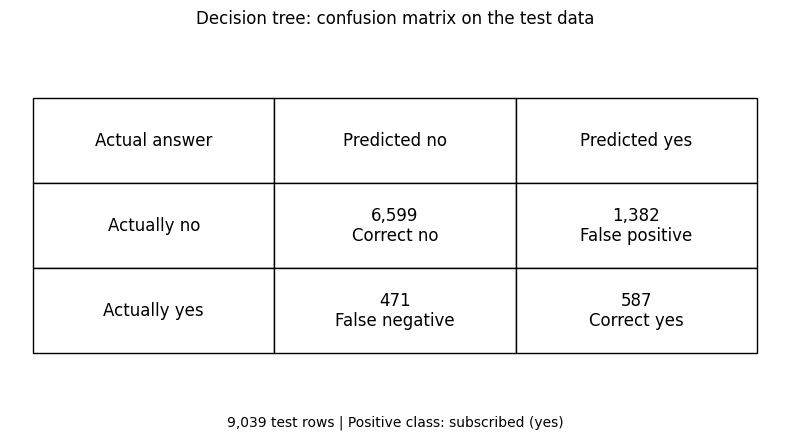

Correct yes predictions: 587
Subscribers missed: 471
Incorrect yes predictions: 1,382


In [9]:
charts_dir = OUTPUT_DIR / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
TN, FP, FN, TP = [int(value) for value in cm.ravel()]
assert TN + FP + FN + TP == len(y_test)
assert np.isclose((TN + TP) / len(y_test), metrics["decision_tree_test"]["accuracy"])
metrics["confusion_matrix"] = {
    "row_order_actual": ["no", "yes"],
    "column_order_predicted": ["no", "yes"],
    "counts": cm.tolist(),
    "true_negatives": TN, "false_positives": FP,
    "false_negatives": FN, "true_positives": TP,
}

# A table-style chart keeps the actual/predicted labels and counts easy to read.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")
table = ax.table(
    cellText=[
        ["Actually no", f"{TN:,}\nCorrect no", f"{FP:,}\nFalse positive"],
        ["Actually yes", f"{FN:,}\nFalse negative", f"{TP:,}\nCorrect yes"],
    ],
    colLabels=["Actual answer", "Predicted no", "Predicted yes"],
    cellLoc="center", loc="center", bbox=[0.03, 0.14, 0.94, 0.72],
)
table.auto_set_font_size(False)
table.set_fontsize(12)
ax.set_title("Decision tree: confusion matrix on the test data", pad=18)
fig.text(0.5, 0.04, f"{len(y_test):,} test rows | Positive class: subscribed (yes)", ha="center")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(charts_dir / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Correct yes predictions: {TP:,}")
print(f"Subscribers missed: {FN:,}")
print(f"Incorrect yes predictions: {FP:,}")


## 9. Rank the five most important input features

An **input feature** is a piece of information the model uses, such as job type or housing-loan status.

The tree gives features scores based on how much their questions helped separate the training examples into clearer yes and no groups. These are called **impurity-based importance scores**. A higher score means a larger contribution to those improvements during training, not necessarily that the feature was used more often.

One-hot encoding creates several columns for a category feature. This step adds their scores together so the chart ranks the original features rather than each individual category. It saves both rankings and shows the five highest-scoring original features.

An importance score is not a subscription probability and does not show what caused customers to subscribe. Features with many possible values can receive higher scores more easily, and related features can share importance.

[Reference: feature-importance limitations](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.feature_importances_)

,original_feature,importance
0,poutcome,0.416981
1,contact,0.231355
2,month,0.184974
3,housing,0.113204
4,campaign,0.028293


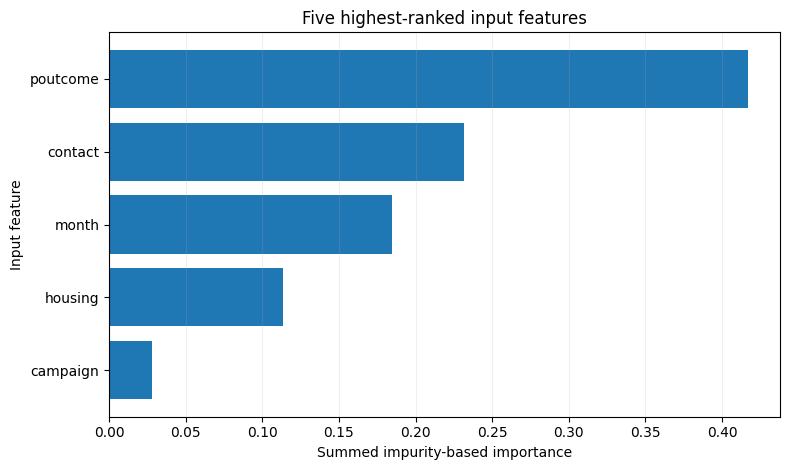

In [10]:
trained_preprocessor = model.named_steps["prepare"]
trained_tree = model.named_steps["tree"]
encoded_names = trained_preprocessor.get_feature_names_out()
encoder = trained_preprocessor.named_transformers_["categorical"].named_steps["encode"]

# The transformer outputs numerical columns first, then the one-hot columns.
original_feature_names = list(NUMERIC_FEATURES)
for column, categories in zip(CATEGORICAL_FEATURES, encoder.categories_):
    original_feature_names.extend([column] * len(categories))
assert len(encoded_names) == len(original_feature_names) == len(trained_tree.feature_importances_)

encoded_importances = pd.DataFrame({
    "encoded_feature": encoded_names,
    "original_feature": original_feature_names,
    "importance": trained_tree.feature_importances_,
})
feature_importances = (
    encoded_importances.groupby("original_feature", as_index=False)["importance"].sum()
    .sort_values(["importance", "original_feature"], ascending=[False, True])
    .reset_index(drop=True)
)
top_five = feature_importances.head(5).copy()
display(top_five)

plot_data = top_five.sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(plot_data["original_feature"], plot_data["importance"])
ax.set(
    title="Five highest-ranked input features",
    xlabel="Summed impurity-based importance", ylabel="Input feature",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(charts_dir / "top_five_features.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


## 10. Look at the first questions in the tree

This chart shows the first three levels of the trained tree, starting with the top question. It is a preview, not the complete tree. A box marked `(...)` means more branches continue below it.

At each question, follow the left branch when the condition is true and the right branch when it is false.

For a one-hot category column, 1 means the category applies and 0 means it does not. A question such as `poutcome_success <= 0.5` therefore asks whether the previous campaign outcome was **not** recorded as success.

The displayed class values take account of the training weights. They are not raw customer counts. For example, a displayed split of 0.5 and 0.5 does not mean half the original records were subscribers.

This chart explains how this particular tree makes its decisions. It does not establish rules that all bank customers follow.

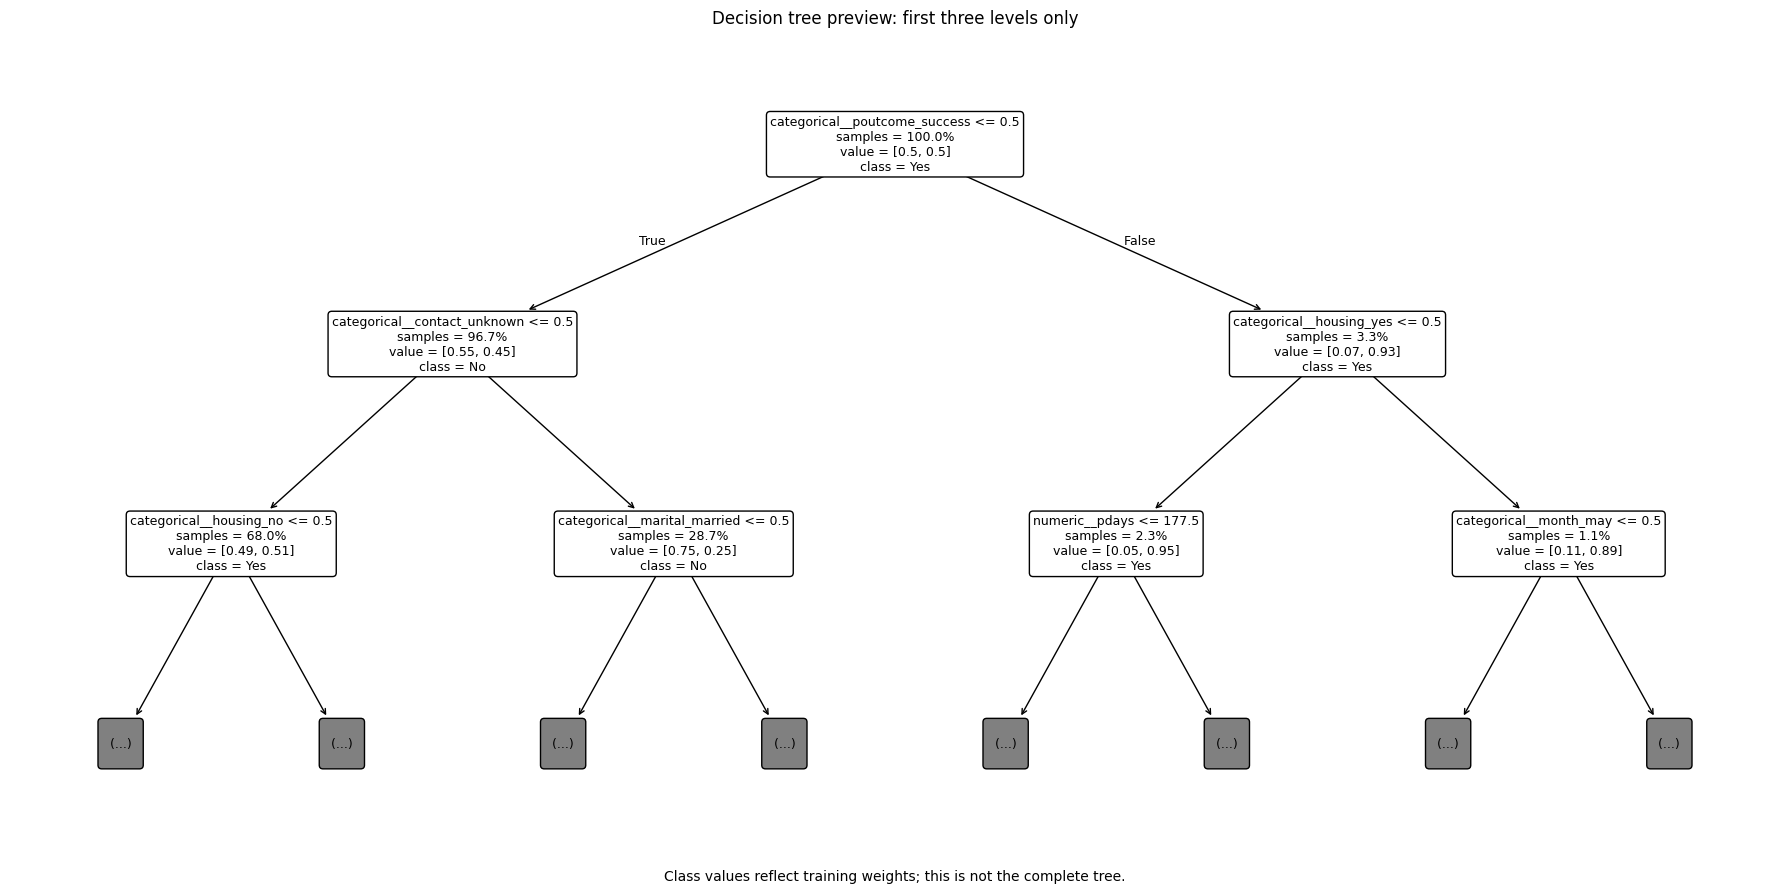

In [11]:
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    trained_tree,
    max_depth=2,
    feature_names=list(encoded_names),
    class_names=["No", "Yes"],
    filled=False,
    rounded=True,
    impurity=False,
    proportion=True,
    precision=2,
    fontsize=9,
    ax=ax,
)
ax.set_title("Decision tree preview: first three levels only", pad=15)
fig.text(0.5, 0.015, "Class values reflect training weights; this is not the complete tree.", ha="center")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(charts_dir / "tree_preview.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)


## 11. Interpret the model results

The paragraph below is built from the actual test results. It compares the model with the baseline and explains both the subscribers found and the mistakes made. A higher accuracy alone does not establish that a model is useful for a marketing campaign.

The effect of missed subscribers versus unnecessary contacts would depend on real business costs, which this project does not estimate. The feature ranking describes this model, not the reasons people make financial decisions.


In [12]:
test_metrics = metrics["decision_tree_test"]
baseline_metrics = metrics["majority_baseline_test"]
ranked_names = ", ".join(top_five["original_feature"].tolist())
model_summary = (
    f"The decision tree was trained on {len(X_train):,} rows and tested on {len(X_test):,} "
    f"held-out rows. Test accuracy was {test_metrics['accuracy']:.2%}, compared with "
    f"{baseline_metrics['accuracy']:.2%} for the majority-class baseline. For subscribers "
    f"(yes), precision was {test_metrics['precision_yes']:.2%} and recall was "
    f"{test_metrics['recall_yes']:.2%}. The tree identified {TP:,} actual subscribers, "
    f"missed {FN:,}, and incorrectly predicted yes for {FP:,} non-subscribers. "
    "These counts show why accuracy must be considered alongside precision and recall.\n\n"
    f"The five highest-ranked inputs were {ranked_names}, using summed training-tree "
    "importance scores. These scores describe model usage, not causes of subscription. "
    "Call duration was excluded because its final value is unavailable before a call ends. "
    "Preparation was fitted only on training data. A limited tree depth and minimum leaf "
    "size controlled complexity; the settings were not selected using test scores. "
    "This is a retrospective random-row evaluation of historical data, not proof of "
    "performance on future campaigns or different customers. Class weighting can trade "
    "more identified subscribers for more incorrect yes predictions. The model is an "
    "educational prototype, not ready for customer decisions."
)
display(Markdown(model_summary))
print("Summary word count:", len(model_summary.split()))


The decision tree was trained on 36,156 rows and tested on 9,039 held-out rows. Test accuracy was 79.50%, compared with 88.30% for the majority-class baseline. For subscribers (yes), precision was 29.81% and recall was 55.48%. The tree identified 587 actual subscribers, missed 471, and incorrectly predicted yes for 1,382 non-subscribers. These counts show why accuracy must be considered alongside precision and recall.

The five highest-ranked inputs were poutcome, contact, month, housing, campaign, using summed training-tree importance scores. These scores describe model usage, not causes of subscription. Call duration was excluded because its final value is unavailable before a call ends. Preparation was fitted only on training data. A limited tree depth and minimum leaf size controlled complexity; the settings were not selected using test scores. This is a retrospective random-row evaluation of historical data, not proof of performance on future campaigns or different customers. Class weighting can trade more identified subscribers for more incorrect yes predictions. The model is an educational prototype, not ready for customer decisions.

Summary word count: 167


## 12. Save the project files and README

This step saves the original CSV, its source information, the cleaning record, the train/test row assignments, the scores, predictions and feature rankings. The README explains how to repeat the work and displays the charts and model summary.

The exact package versions used for this run are saved in `requirements.txt`. No saved model object is needed: the notebook contains the steps to train it again. The dataset is credited to its authors under the licence listed by UCI.

The notebook contains the explanations and analysis code. The exported files contain the data, charts and reports. The notebook itself is not included in the ZIP.

In [13]:
data_dir = OUTPUT_DIR / "data"
data_dir.mkdir(parents=True, exist_ok=True)

run_versions = {
    package: importlib.metadata.version(package)
    for package in ["pandas", "numpy", "matplotlib", "scikit-learn"]
}
model_settings = {
    "run_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "software_versions": run_versions,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "split": "stratified random row-level split",
    "max_depth": MAX_DEPTH,
    "min_samples_leaf": MIN_SAMPLES_LEAF,
    "class_weight": CLASS_WEIGHT,
    "positive_class": "yes (1)",
    "excluded_feature": "duration",
    "input_features": FEATURES,
    "numeric_missing_values": "training median",
    "categorical_missing_values": "constant missing label",
    "categorical_encoding": "one-hot, ignore unseen categories",
    "unknown_category": "retained as an explicit category",
    "pdays_minus_one": "retained; means no previous campaign contact",
    "hyperparameter_selection": "fixed starting values; no test-set tuning",
    "feature_importance": "training impurity reduction summed to original input columns",
}

(data_dir / "source_bank_full.csv").write_bytes(source_csv_bytes)
(data_dir / "source_metadata.json").write_text(json.dumps(source_metadata, indent=2), encoding="utf-8")
(data_dir / "cleaning_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
split_indices.to_csv(data_dir / "split_indices.csv", index=False)

(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(OUTPUT_DIR / "model_settings.json").write_text(json.dumps(model_settings, indent=2), encoding="utf-8")
(OUTPUT_DIR / "model_summary.md").write_text(model_summary + "\n", encoding="utf-8")
(OUTPUT_DIR / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in run_versions.items()) + "\n",
    encoding="utf-8",
)
feature_importances.to_csv(OUTPUT_DIR / "feature_importances.csv", index=False)
encoded_importances.to_csv(OUTPUT_DIR / "encoded_feature_importances.csv", index=False)

predictions = pd.DataFrame({
    "source_row": X_test.index,
    "actual": np.asarray(y_test),
    "predicted": y_pred,
    "baseline_predicted": baseline_pred,
})
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

metric_markdown = (
    "| Measure | Decision tree | Majority baseline |\n"
    "|---|---:|---:|\n"
    f"| Test accuracy | {test_metrics['accuracy']:.2%} | {baseline_metrics['accuracy']:.2%} |\n"
    f"| Precision (yes) | {test_metrics['precision_yes']:.2%} | {baseline_metrics['precision_yes']:.2%} |\n"
    f"| Recall (yes) | {test_metrics['recall_yes']:.2%} | {baseline_metrics['recall_yes']:.2%} |\n"
)
importance_markdown = "| Input feature | Importance |\n|---|---:|\n" + "".join(
    f"| {row.original_feature} | {row.importance:.4f} |\n"
    for row in top_five.itertuples(index=False)
)

readme = f"""# Bank Marketing: Decision Tree Classifier
**Maryam Chaudhry | ArithMatrix AVIP 2026 | Data Science Task 4**

## Project question
Can a decision tree classify whether a customer subscribed to a term deposit, using recorded customer and campaign information? The target is `y`: no = 0, yes = 1. This is an educational analysis, not a loan-approval or production marketing system.

## Data source and attribution
[UCI Bank Marketing dataset]({DATASET_PAGE}). Selected file: **bank-full.csv**.
{source_metadata['citation']}
Dataset licence listed by UCI: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
The saved CSV is the original source snapshot. Prepared rows are changed only as documented below.
Original download time (UTC): **{source_metadata['retrieved_at_utc']}**.
Source rows: **{len(raw):,}**. Retained model rows: **{len(X):,}**.
The matching fingerprint and download address are in `data/source_metadata.json`.

## Run the notebook
Open `{NOTEBOOK_NAME}` in Google Colab or Jupyter. Run the code cells from top to bottom. The installation cell installs the packages; the download cell reads the selected UCI CSV. An internet connection is needed for a fresh download.

To reproduce with the saved data, make `data/source_bank_full.csv` and `data/source_metadata.json` available in the notebook runtime. Change `LOCAL_CSV` and `LOCAL_METADATA` in Section 2 to their actual paths. Leave both as `None` to download again. The loader checks that the saved CSV matches its metadata.

For a local Jupyter environment, install the saved package versions with:

```bash
python -m pip install -r requirements.txt
```

The notebook contains the explanations, data preparation, model training and evaluation code. The ZIP export contains results and supporting files, not a second copy of the notebook. Run metadata includes the Python and package versions; matching versions and source data improves reproducibility.

## Preparation and model
Call `duration` is excluded because its final value would not be available before a call ends. The target `y` is also excluded from inputs.

Text is tidied, invalid target rows are removed, and exact duplicates across the selected inputs and target are removed before splitting. `unknown` stays a category. Negative balances and `pdays=-1` are not treated as missing. The latter marks no previous-campaign contact. All changes are recorded in `data/cleaning_audit.json`.

There are **{len(X_train):,} training rows** and **{len(X_test):,} test rows**, with a stratified {1 - TEST_SIZE:.0%}/{TEST_SIZE:.0%} random row split and seed {RANDOM_STATE}. Training-only medians fill missing numeric values. Missing categories receive a `missing` label; one-hot encoding handles categorical inputs and tolerates unseen test categories. These transformations are fitted within the pipeline using training rows only.

The classifier uses `max_depth={MAX_DEPTH}`, `min_samples_leaf={MIN_SAMPLES_LEAF}` and `class_weight={CLASS_WEIGHT!r}`. These are fixed starting settings, not test-selected optimum values. Class weighting changes training weights, not row counts. The majority baseline always predicts the most common training outcome.

## Test results
Precision and recall use subscription (yes = 1) as the positive class. Undefined precision is recorded as zero when no yes predictions are made; the predicted-yes count is in `metrics.json`.

{metric_markdown}
Training accuracy: **{metrics['decision_tree_training_accuracy']:.2%}**.

![Confusion matrix: actual answers in rows, predictions in columns](charts/confusion_matrix.png)

## Top five input features
Importance scores measure the tree's training split usage, summed over one-hot columns belonging to the same original feature. They are not causal effects and can favour inputs with many possible split values.

{importance_markdown}
![Top five original input features](charts/top_five_features.png)

## Tree preview
Only the first three levels are displayed. Class values reflect training weights, not raw customer counts.

![First three tree levels](charts/tree_preview.png)

## Model summary
{model_summary}

## Limitations and responsible use
This is a random-row, historical evaluation, not an out-of-time test. There is no identifier to guarantee that customers in the test data are absent from training. Some recorded fields describe the latest contact; their availability must be checked for any intended prediction time. Removing duration alone is not a complete deployment audit.

Results depend on this dataset, split, software and model settings. No real marketing costs or subgroup fairness tests are included. Demographic inputs may create unfair patterns, so this prototype should not make decisions about real customers. Scores do not establish causation, suitability for deployment or future performance. Further tuning should use validation inside the training data, not repeated choices based on this test set.

## Project files
- `{NOTEBOOK_NAME}`: explanations, preparation, training and evaluation code, saved separately.
- `charts/`: confusion matrix, top-five feature chart and optional tree preview.
- `metrics.json`: test scores, baseline scores and confusion-matrix counts.
- `model_summary.md`: interpretation of the measured results.
- `model_settings.json`: model choices, random seed and run software versions.
- `feature_importances.csv`: full ranking of original input features.
- `encoded_feature_importances.csv`: individual encoded-column scores.
- `test_predictions.csv`: row numbers and actual/predicted labels, no customer names.
- `data/`: source CSV, source details, cleaning audit and train/test row numbers.
- `requirements.txt`: package versions used in this run.

## AI assistance
This project was prepared with AI assistance. The code calculates its scores from the cited data. AI-generated explanations do not replace checking the calculations and limitations.

## Technical references
- [Avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html)
- [Recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html)
- [DummyClassifier baseline](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
"""
(OUTPUT_DIR / "README.md").write_text(readme, encoding="utf-8")
print("Saved the README, source data, model results, settings and interpretation.")


Saved the README, source data, model results, settings and interpretation.


## 13. Check the export and download the ZIP

This cell checks that the required output files exist, that the confusion-matrix counts account for every test row, and that the scores lie between zero and one. It then creates a ZIP containing only the listed project outputs.

These checks do not prove that the model is accurate, fair or ready for real use.


In [14]:
expected_files = [
    "README.md", "requirements.txt", "model_summary.md", "metrics.json", "model_settings.json",
    "feature_importances.csv", "encoded_feature_importances.csv", "test_predictions.csv",
    "data/source_bank_full.csv", "data/source_metadata.json", "data/cleaning_audit.json",
    "data/split_indices.csv", "charts/confusion_matrix.png", "charts/top_five_features.png",
    "charts/tree_preview.png",
]
for name in expected_files:
    path = OUTPUT_DIR / name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty output: {name}. Run the earlier cells first.")

assert len(predictions) == len(X_test) == sum(sum(row) for row in cm.tolist())
assert set(split_indices["split"]) == {"train", "test"}
assert split_indices["source_row"].is_unique
for result_name in ["decision_tree_test", "majority_baseline_test"]:
    for metric_name in ["accuracy", "precision_yes", "recall_yes"]:
        assert 0 <= metrics[result_name][metric_name] <= 1
assert len(top_five) == 5
assert "duration" not in feature_importances["original_feature"].values

zip_path = Path(f"{REPOSITORY_NAME}_upload.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in expected_files:
        archive.write(OUTPUT_DIR / name, arcname=name)

print(f"Created {zip_path.name} containing {len(expected_files)} project files.")
print(f"Also save this notebook separately as {NOTEBOOK_NAME}.")
try:
    from google.colab import files
except ImportError:
    print("Outside Colab: the ZIP is saved at", zip_path.resolve())
else:
    files.download(str(zip_path))


Created DS_4_DecisionTreeClassifier_BYTE_upload.zip containing 15 project files.
Also save this notebook separately as Bank_Marketing_Decision_Tree_Task_4.ipynb.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>